# Multi-seed SGD vs. SDE approximations on a 2D quadratic

This notebook simulates:

- SGD
- First-order literature SDE
- Second-order literature SDE
- New stability-adjusted SDE

The experiment is run over multiple seeds. For each seed, all methods use the same seed. The three SDEs also receive the same Brownian increments at every Euler--Maruyama step.

Important implementation details:

- The Euler--Maruyama step is `dt = alpha * eta`.
- The SDE noise increment is implemented as `sqrt(alpha) * eta * Sigma_sqrt @ z`, which is equivalent to `sqrt(eta) * sqrt(dt) * Sigma_sqrt @ z`.
- Quantitative comparisons between SGD and the SDEs are performed only at SGD times `t_k = k * eta` by subsampling the SDE paths with `stride = round(1 / alpha)`.


In [1]:

import numpy as np
import matplotlib.pyplot as plt



## Problem: 2D convex quadratic


In [2]:

def make_quadratic(lambdas=(1.0, 10.0)):
    """
    f(x) = 1/2 x^T A x, with A symmetric positive definite.
    """
    A = np.diag(lambdas)

    def f(x):
        return 0.5 * x @ A @ x

    def grad_f(x):
        return A @ x

    def hess_f(x):
        return A

    return A, f, grad_f, hess_f



## Drift definitions


In [3]:

def drift_sde_fo(x, eta, grad_f, hess_f):
    """
    Literature first-order SDE:
        dX_t = - grad f(X_t) dt + sqrt(eta Sigma) dW_t
    """
    return -grad_f(x)


def drift_sde_so_literature(x, eta, grad_f, hess_f):
    """
    Literature second-order SDE:
        dX_t = - grad f(X_t) dt
               - eta/2 Hess f(X_t) grad f(X_t) dt
               + sqrt(eta Sigma) dW_t
    """
    g = grad_f(x)
    H = hess_f(x)
    return -g - 0.5 * eta * (H @ g)


def drift_sde_new(x, eta, grad_f, hess_f):
    """
    New stability-adjusted SDE:
        dX_t = - grad f(X_t) dt
               + eta/2 Hess f(X_t) grad f(X_t) dt
               + sqrt(eta Sigma) dW_t
    """
    g = grad_f(x)
    H = hess_f(x)
    return -g + 0.5 * eta * (H @ g)



## Euler--Maruyama simulator for the SDEs


In [4]:
def simulate_sdes_euler_maruyama(
    x0,
    eta,
    alpha,
    num_em_steps,
    Sigma,
    grad_f,
    hess_f,
    f,
    seed=0,
):
    """
    Simulates all three SDEs using Euler--Maruyama.

    Important:
    - alpha*eta is the Euler--Maruyama step and does NOT need to equal eta.
    - The three SDEs receive the exact same Brownian noise increment
      at each Euler--Maruyama step.
    - Since dt = alpha*eta, the stochastic increment
          sqrt(eta) * sqrt(dt) * Sigma_sqrt @ z
      is implemented as
          sqrt(alpha) * eta * Sigma_sqrt @ z.
    """

    rng = np.random.default_rng(seed)
    d = len(x0)

    Sigma_sqrt = np.linalg.cholesky(Sigma)

    names = [
        "SDE FO literature",
        "SDE SO literature",
        "SDE new",
    ]

    drifts = {
        "SDE FO literature": drift_sde_fo,
        "SDE SO literature": drift_sde_so_literature,
        "SDE new": drift_sde_new,
    }

    xs = {name: np.zeros((num_em_steps + 1, d)) for name in names}
    losses = {name: np.zeros(num_em_steps + 1) for name in names}

    for name in names:
        xs[name][0] = x0
        losses[name][0] = f(x0)

    # Shared Brownian noise across all SDEs.
    z_all = rng.normal(size=(num_em_steps, d))

    for k in range(num_em_steps):
        z = z_all[k]
        dW_noise = Sigma_sqrt @ z

        for name in names:
            x = xs[name][k]
            b = drifts[name](x, eta, grad_f, hess_f)

            xs[name][k + 1] = x + b * alpha * eta + dW_noise * np.sqrt(alpha) * eta
            losses[name][k + 1] = f(xs[name][k + 1])

    times = np.arange(num_em_steps + 1) * alpha * eta

    return times, xs, losses



## SGD simulator


In [5]:

def simulate_sgd(
    x0,
    eta,
    num_sgd_steps,
    Sigma,
    grad_f,
    f,
    seed=0,
):
    """
    Simulates discrete-time SGD:

        x_{k+1} = x_k - eta (grad f(x_k) - noise_k)

    where

        noise_k ~ N(0, Sigma).

    With the SDE time convention, SGD step k corresponds to time t = k eta.
    """

    rng = np.random.default_rng(seed)
    d = len(x0)

    Sigma_sqrt = np.linalg.cholesky(Sigma)

    xs = np.zeros((num_sgd_steps + 1, d))
    losses = np.zeros(num_sgd_steps + 1)

    xs[0] = x0
    losses[0] = f(x0)

    for k in range(num_sgd_steps):
        x = xs[k]
        noise = Sigma_sqrt @ rng.normal(size=d)

        xs[k + 1] = x - eta * (grad_f(x) - noise)
        losses[k + 1] = f(xs[k + 1])

    times = np.arange(num_sgd_steps + 1) * eta

    return times, xs, losses



## Multi-seed runner


In [6]:

def run_many_seeds(
    seeds,
    x0,
    eta,
    alpha,
    num_em_steps,
    num_sgd_steps,
    Sigma,
    grad_f,
    hess_f,
    f,
):
    """
    Runs all methods over multiple seeds and returns seed-averaged
    trajectories and losses.

    For each seed, the same seed is used for all methods.
    Inside simulate_sdes_euler_maruyama, the three SDEs also receive
    exactly the same Brownian noise increments.
    """

    xs_sde_all = None
    losses_sde_all = None
    xs_sgd_all = []
    losses_sgd_all = []

    for seed in seeds:
        times_sde, xs_sde, losses_sde = simulate_sdes_euler_maruyama(
            x0=x0,
            eta=eta,
            alpha=alpha,
            num_em_steps=num_em_steps,
            Sigma=Sigma,
            grad_f=grad_f,
            hess_f=hess_f,
            f=f,
            seed=seed,
        )

        times_sgd, xs_sgd, losses_sgd = simulate_sgd(
            x0=x0,
            eta=eta,
            num_sgd_steps=num_sgd_steps,
            Sigma=Sigma,
            grad_f=grad_f,
            f=f,
            seed=seed,
        )

        if xs_sde_all is None:
            xs_sde_all = {name: [] for name in xs_sde}
            losses_sde_all = {name: [] for name in losses_sde}

        for name in xs_sde:
            xs_sde_all[name].append(xs_sde[name])
            losses_sde_all[name].append(losses_sde[name])

        xs_sgd_all.append(xs_sgd)
        losses_sgd_all.append(losses_sgd)

    xs_sde_mean = {
        name: np.mean(np.stack(paths, axis=0), axis=0)
        for name, paths in xs_sde_all.items()
    }
    losses_sde_mean = {
        name: np.mean(np.stack(paths, axis=0), axis=0)
        for name, paths in losses_sde_all.items()
    }

    xs_sgd_mean = np.mean(np.stack(xs_sgd_all, axis=0), axis=0)
    losses_sgd_mean = np.mean(np.stack(losses_sgd_all, axis=0), axis=0)

    return (
        times_sde,
        xs_sde_mean,
        losses_sde_mean,
        times_sgd,
        xs_sgd_mean,
        losses_sgd_mean,
    )


## Compare SDE losses at SGD times

The SDE paths live on the Euler--Maruyama grid, while SGD lives on the coarser grid `t_k = k * eta`.
For quantitative SGD-vs-SDE comparisons, we therefore subsample the SDE losses with `stride = round(1 / alpha)`.


In [7]:
def sde_losses_at_sgd_times(losses_sde, alpha, num_sgd_steps):
    """
    Subsamples SDE losses at SGD times.

    This assumes dt = alpha * eta and compares against SGD times t_k = k * eta.
    Therefore one SGD step corresponds to stride = round(1 / alpha) EM steps.
    """
    stride = round(1 / alpha)

    if stride <= 0:
        raise ValueError("alpha must be positive.")

    if not np.isclose(stride * alpha, 1.0):
        raise ValueError(
            "For this simple subsampling comparison, 1 / alpha should be an integer. "
            f"Got alpha={alpha}, round(1/alpha)={stride}."
        )

    return {
        name: loss_path[::stride][: num_sgd_steps + 1]
        for name, loss_path in losses_sde.items()
    }


def print_loss_error_summary(losses_sde_at_sgd_times, losses_sgd):
    """
    Prints absolute loss errors between each SDE and SGD, evaluated only at SGD times.
    """
    print("Loss comparison at SGD times")
    print("-" * 72)
    print(f"{'method':<24} {'mean abs error':>16} {'final abs error':>16} {'final rel error':>16}")
    print("-" * 72)

    for name, loss_path in losses_sde_at_sgd_times.items():
        n = min(len(loss_path), len(losses_sgd))
        error = loss_path[:n] - losses_sgd[:n]
        abs_error = np.abs(error)
        final_rel_error = abs_error[-1] / max(abs(losses_sgd[n - 1]), 1e-12)

        print(
            f"{name:<24} "
            f"{np.mean(abs_error):>16.6e} "
            f"{abs_error[-1]:>16.6e} "
            f"{final_rel_error:>16.6e}"
        )


def plot_loss_errors_at_sgd_times(times_sgd, losses_sde_at_sgd_times, losses_sgd):
    """
    Plots absolute loss errors between each SDE and SGD, evaluated only at SGD times.
    """
    plt.figure(figsize=(8, 5))

    for name, loss_path in losses_sde_at_sgd_times.items():
        n = min(len(loss_path), len(losses_sgd), len(times_sgd))
        error = np.abs(loss_path[:n] - losses_sgd[:n])
        plt.plot(times_sgd[:n], error, label=name)

    plt.xlabel("time")
    plt.ylabel(r"$|f(X_t^{SDE}) - f(x_k^{SGD})|$")
    plt.yscale("log")
    plt.title("Absolute loss error at SGD times")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()



## Plotting


In [8]:
def plot_losses(times_sde, losses_sde, times_sgd, losses_sgd):
    plt.figure(figsize=(8, 5))

    for name, loss_path in losses_sde.items():
        plt.plot(times_sde, loss_path, label=name)

    plt.plot(times_sgd, losses_sgd, "--", label="SGD")

    plt.xlabel("time")
    plt.ylabel(r"$f(x)$")
    plt.yscale("log")
    plt.title("Seed-averaged loss curves")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Main experiment

Change `seeds`, `eta`, `dt`, `total_time`, `Sigma`, or the quadratic eigenvalues below.


In [9]:

# -----------------------------
# Quadratic setup
# -----------------------------
A, f, grad_f, hess_f = make_quadratic(lambdas=(1.0, 10.0))

x0 = np.array([2.0, 2.0])

# -----------------------------
# Algorithm / SDE parameters
# -----------------------------
eta = 0.1

# Euler--Maruyama step.
# This does not need to equal eta.
alpha = 0.1
N_Seeds = 200

total_time = 8.0

num_em_steps = round(total_time / (alpha * eta))
num_sgd_steps = round(total_time / eta)
stride = round(1 / alpha)

if not np.isclose(stride * alpha, 1.0):
    raise ValueError("For this simple comparison, 1 / alpha should be an integer.")

# Constant gradient-noise covariance.
Sigma = 0.5 * np.eye(2)

# Multiple seeds. For each seed, all methods use the same seed.
seeds = list(range(123, 123 + N_Seeds))

print(f"Number of seeds: {len(seeds)}")
print(f"Euler--Maruyama steps: {num_em_steps}")
print(f"SGD steps: {num_sgd_steps}")
print(f"SDE subsampling stride for SGD-time comparison: {stride}")


Number of seeds: 200
Euler--Maruyama steps: 800
SGD steps: 80
SDE subsampling stride for SGD-time comparison: 10


In [10]:

(
    times_sde,
    xs_sde_mean,
    losses_sde_mean,
    times_sgd,
    xs_sgd_mean,
    losses_sgd_mean,
) = run_many_seeds(
    seeds=seeds,
    x0=x0,
    eta=eta,
    alpha=alpha,
    num_em_steps=num_em_steps,
    num_sgd_steps=num_sgd_steps,
    Sigma=Sigma,
    grad_f=grad_f,
    hess_f=hess_f,
    f=f,
)


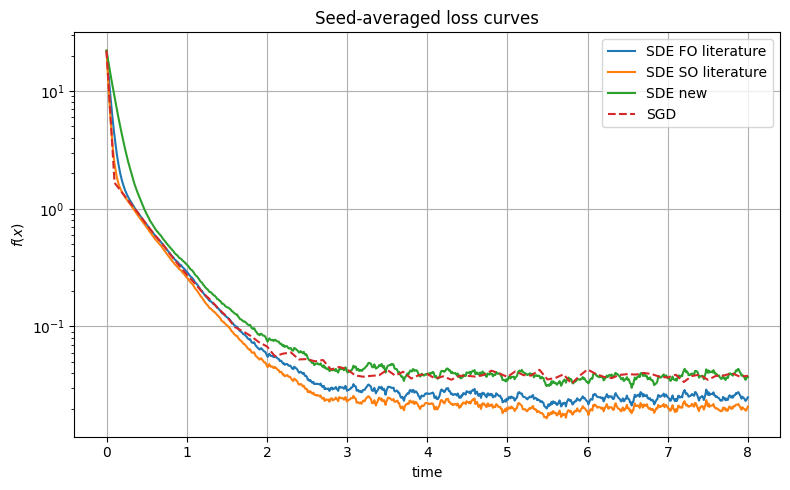

Loss comparison at SGD times
------------------------------------------------------------------------
method                     mean abs error  final abs error  final rel error
------------------------------------------------------------------------
SDE FO literature            4.492670e-02     1.308267e-02     3.436635e-01
SDE SO literature            2.830204e-02     1.720098e-02     4.518459e-01
SDE new                      1.508551e-01     8.884505e-04     2.333836e-02


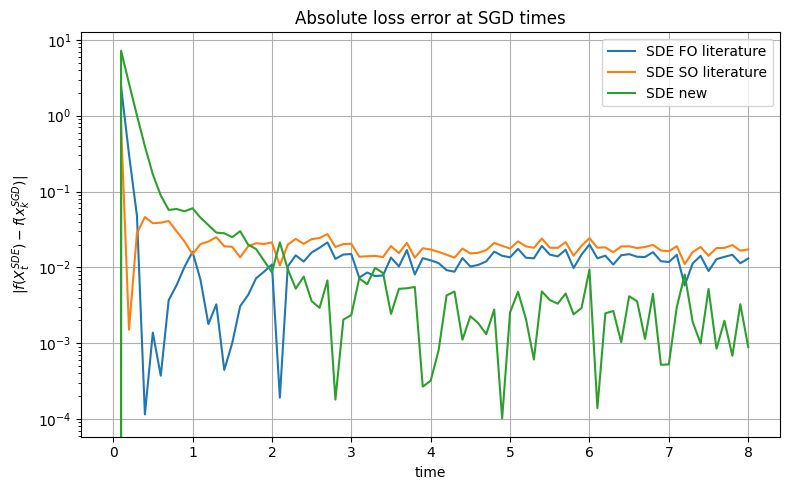

In [11]:
plot_losses(times_sde, losses_sde_mean, times_sgd, losses_sgd_mean)

losses_sde_at_sgd_times = sde_losses_at_sgd_times(
    losses_sde=losses_sde_mean,
    alpha=alpha,
    num_sgd_steps=num_sgd_steps,
)

print_loss_error_summary(losses_sde_at_sgd_times, losses_sgd_mean)
plot_loss_errors_at_sgd_times(times_sgd, losses_sde_at_sgd_times, losses_sgd_mean)


In [12]:

# -----------------------------
# Quadratic setup
# -----------------------------
A, f, grad_f, hess_f = make_quadratic(lambdas=(1.0, 10.0))

x0 = np.array([2.0, 2.0])

# -----------------------------
# Algorithm / SDE parameters
# -----------------------------
eta = 0.21

# Euler--Maruyama step.
# This does not need to equal eta.
alpha = 0.1

total_time = 8.0

num_em_steps = round(total_time / (alpha * eta))
num_sgd_steps = round(total_time / eta)
stride = round(1 / alpha)

if not np.isclose(stride * alpha, 1.0):
    raise ValueError("For this simple comparison, 1 / alpha should be an integer.")

# Constant gradient-noise covariance.
Sigma = 0.5 * np.eye(2)

# Multiple seeds. For each seed, all methods use the same seed.
seeds = list(range(123, 123 + N_Seeds))

print(f"Number of seeds: {len(seeds)}")
print(f"Euler--Maruyama steps: {num_em_steps}")
print(f"SGD steps: {num_sgd_steps}")
print(f"SDE subsampling stride for SGD-time comparison: {stride}")


Number of seeds: 200
Euler--Maruyama steps: 381
SGD steps: 38
SDE subsampling stride for SGD-time comparison: 10


In [13]:

(
    times_sde,
    xs_sde_mean,
    losses_sde_mean,
    times_sgd,
    xs_sgd_mean,
    losses_sgd_mean,
) = run_many_seeds(
    seeds=seeds,
    x0=x0,
    eta=eta,
    alpha=alpha,
    num_em_steps=num_em_steps,
    num_sgd_steps=num_sgd_steps,
    Sigma=Sigma,
    grad_f=grad_f,
    hess_f=hess_f,
    f=f,
)


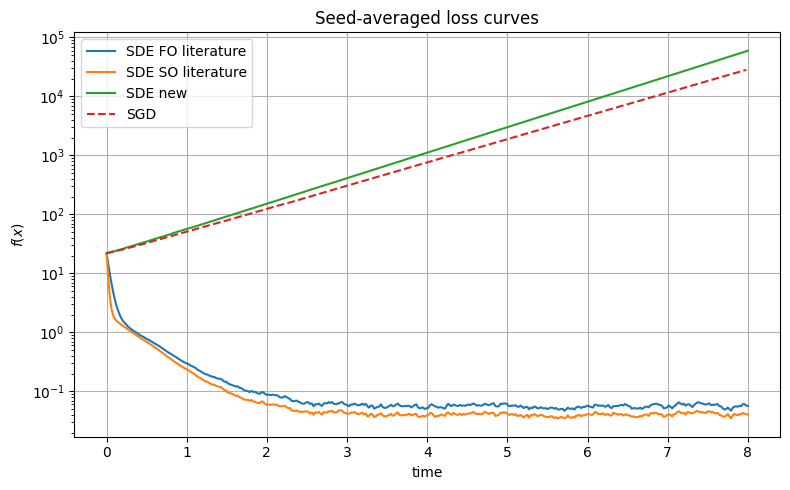

Loss comparison at SGD times
------------------------------------------------------------------------
method                     mean abs error  final abs error  final rel error
------------------------------------------------------------------------
SDE FO literature            4.176088e+03     2.830177e+04     9.999980e-01
SDE SO literature            4.176118e+03     2.830178e+04     9.999986e-01
SDE new                      3.758886e+03     3.007213e+04     1.062551e+00


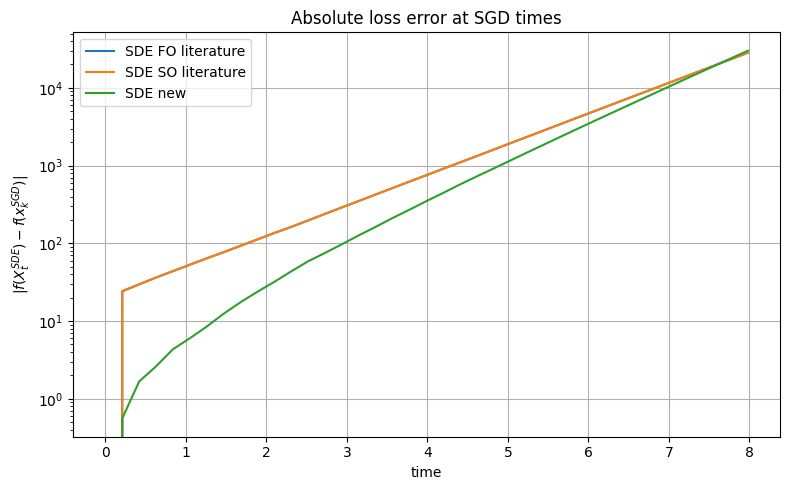

In [14]:
plot_losses(times_sde, losses_sde_mean, times_sgd, losses_sgd_mean)

losses_sde_at_sgd_times = sde_losses_at_sgd_times(
    losses_sde=losses_sde_mean,
    alpha=alpha,
    num_sgd_steps=num_sgd_steps,
)

print_loss_error_summary(losses_sde_at_sgd_times, losses_sgd_mean)
plot_loss_errors_at_sgd_times(times_sgd, losses_sde_at_sgd_times, losses_sgd_mean)
